In [1]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

df_small = load_breast_cancer()

In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

# Split the data
X_train, X_test, y_train, y_test = train_test_split(df_small.data, df_small.target, test_size=0.2, random_state=42)

# Single Tree
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)
print(f"Single Tree Accuracy: {tree.score(X_test, y_test):.4f}")

Single Tree Accuracy: 0.9474


In [3]:
from sklearn.ensemble import BaggingClassifier

bagging = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100, random_state=42)
bagging.fit(X_train, y_train)
print(f"Bagging Accuracy: {bagging.score(X_test, y_test):.4f}")

Bagging Accuracy: 0.9561


In [4]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42)
rf.fit(X_train, y_train)

print(f"Random Forest Accuracy: {rf.score(X_test, y_test):.4f}")
print(f"Out-of-Bag Score: {rf.oob_score_:.4f}")

Random Forest Accuracy: 0.9649
Out-of-Bag Score: 0.9560


In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor

# Define the range of depths you want to test
#param_grid = {'max_depth': [3, 5, 10, 15, 20, None]}
param_grid = {
    'max_depth': list(range(1, 5)) + [None] 
}

# Use GridSearch to find the best one
grid_search = GridSearchCV(RandomForestClassifier(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

print(f"Best Depth: {grid_search.best_params_}")

Best Depth: {'max_depth': 4}


In [6]:
# Constrained Forest: limiting depth and features to prevent overfitting
rf_tuned = RandomForestClassifier(
    n_estimators=100, 
    max_depth=4,           
    max_features='sqrt',   # Square root of total features (standard for classification)
    oob_score=True, 
    random_state=42
)

rf_tuned.fit(X_train, y_train)

print(f"Tuned RF Accuracy: {rf_tuned.score(X_test, y_test):.4f}")
print(f"Tuned OOB Score: {rf_tuned.oob_score_:.4f}")

Tuned RF Accuracy: 0.9649
Tuned OOB Score: 0.9560


In [7]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_features': ['sqrt', 0.2, 0.5], # Try using only 20% or 50% of features
    'min_samples_leaf': [1, 2, 5],      # Forces leaves to be more stable
    'bootstrap': [True]
}

grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

print(f"New Best Params: {grid_search.best_params_}")
print(f"New Best Score: {grid_search.best_score_:.4f}")

New Best Params: {'bootstrap': True, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
New Best Score: 0.9626


In [8]:
from sklearn.datasets import fetch_openml
df_med = fetch_openml(data_id=1590, as_frame=True, parser='auto')

In [9]:
import pandas as pd

X = df_med.data
y = df_med.target

print(X.info())
print(y.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
dtypes: category(8), int64(6)
memory usage: 2.6 MB
None
class
<=50K    37155
>50K     11687
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split

# Encoding & missing values
x = pd.get_dummies(X, drop_first=True) 
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [11]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

param_grid_bag = {
    'estimator__max_depth': [5, 10, None],
    'n_estimators': [50, 100, 200]
}

bag_test = GridSearchCV(
    BaggingClassifier(estimator=DecisionTreeClassifier(class_weight='balanced')),
    param_grid_bag, cv=3, n_jobs=-1
)
bag_test.fit(X_train, y_train)
print(f"Best Bagging Params: {bag_test.best_params_}")

Best Bagging Params: {'estimator__max_depth': None, 'n_estimators': 100}


In [12]:
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None],               # We know None is best from your previous run
    'max_features': ['sqrt', 0.2, 0.5], # Testing feature randomness
    'min_samples_split': [2, 5, 10],   # Another way to control complexity
    'class_weight': ['balanced']       # Keep this for the income imbalance
}

rf_final_grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=3, n_jobs=-1)
rf_final_grid.fit(X_train, y_train)

print(f"Best RF Params: {rf_final_grid.best_params_}")
print(f"Final Accuracy: {rf_final_grid.score(X_test, y_test):.4f}")

Best RF Params: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 0.2, 'min_samples_split': 5, 'n_estimators': 300}
Final Accuracy: 0.8640


In [13]:
from sklearn.metrics import classification_report

y_pred = rf_final_grid.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       <=50K       0.91      0.91      0.91      7479
        >50K       0.71      0.72      0.71      2290

    accuracy                           0.86      9769
   macro avg       0.81      0.81      0.81      9769
weighted avg       0.86      0.86      0.86      9769



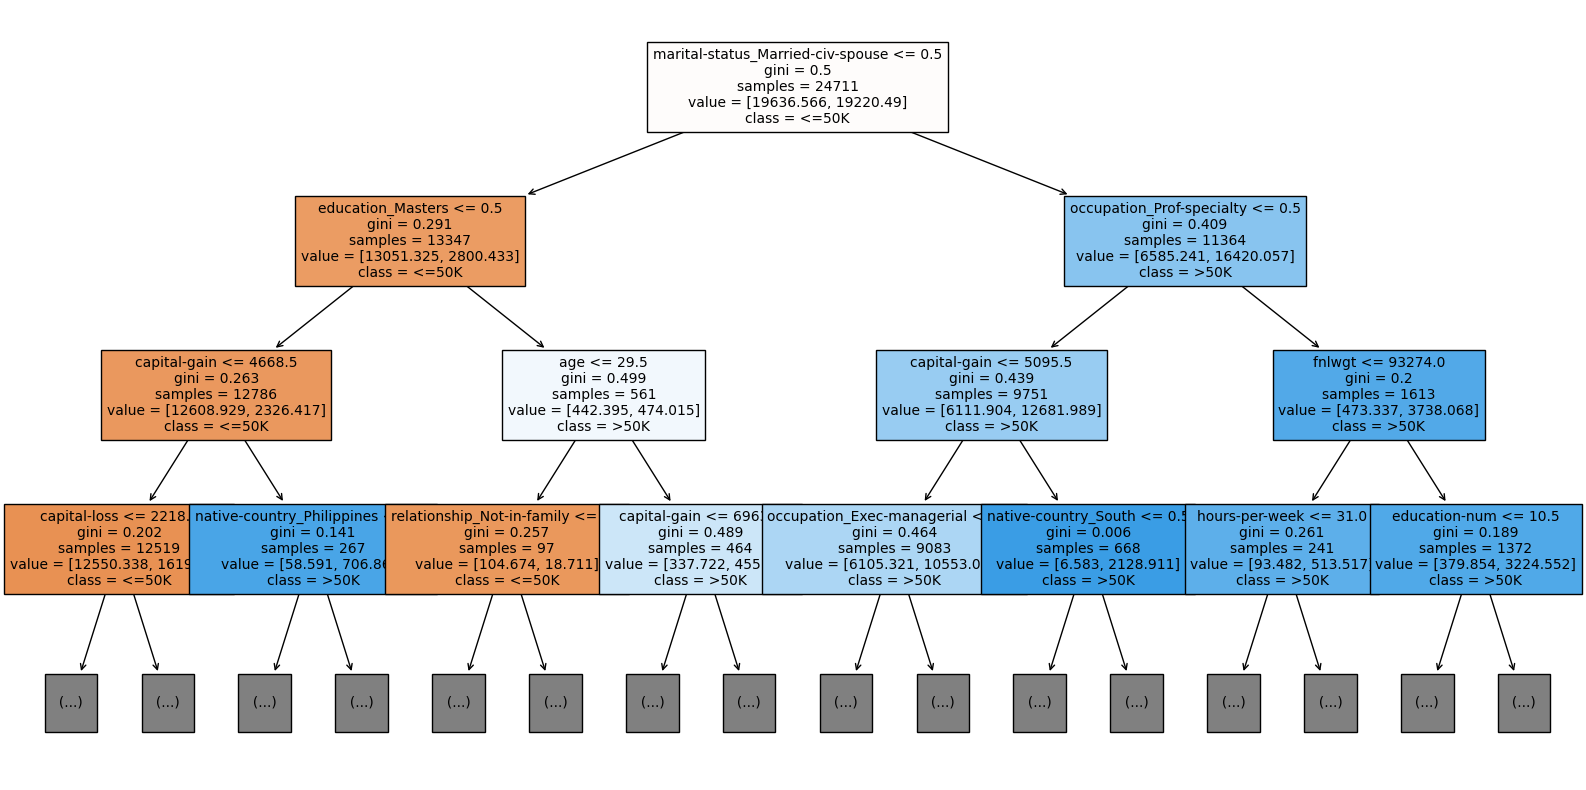

In [14]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Pick one tree from your forest
single_tree = rf_final_grid.best_estimator_.estimators_[0]

plt.figure(figsize=(20, 10))
plot_tree(single_tree, 
          feature_names=x.columns, # Use your encoded column names
          class_names=['<=50K', '>50K'], 
          filled=True, 
          fontsize=10, 
          max_depth=3) 

plt.show()

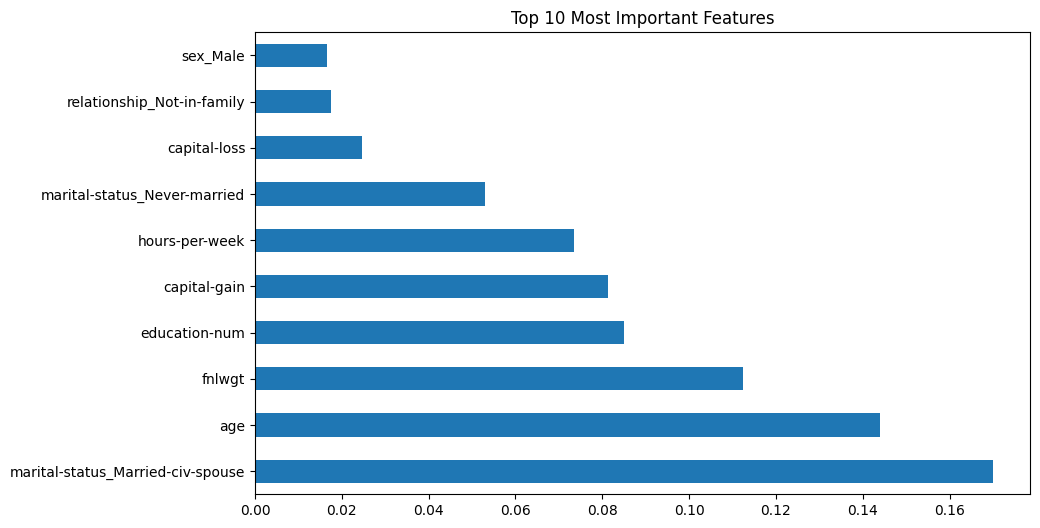

In [15]:
import pandas as pd
import seaborn as sns

# Get importances from the best model
importances = rf_final_grid.best_estimator_.feature_importances_
feat_importances = pd.Series(importances, index=x.columns)

# Plot the top 10
plt.figure(figsize=(10,6))
feat_importances.nlargest(10).plot(kind='barh')
plt.title("Top 10 Most Important Features")
plt.show()

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.datasets import load_wine

wine = load_wine()
x = wine.data
y = wine.target

#stratify ensures a proportional split of classes between test and training sets, 03 test size as it is small
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42, stratify=y)

In [20]:
rf_wine = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42)
rf_wine.fit(x_train, y_train)

print(f"Test Accuracy: {rf_wine.score(x_test, y_test):.4f}")
print(f"OOB Score: {rf_wine.oob_score_:.4f}")

Test Accuracy: 1.0000
OOB Score: 0.9758
